# Deep Ensemble (5 SEED)

Cinco SEED entrenados de forma independiente por fold (semillas 42, 1, 2, 3 y 4); la predicción es la media. La dispersión entre modelos es la incertidumbre epistémica de toda la red, incluido el BiLSTM.


**Datos.** Evaluaciones 0, 1 y 2, cinco folds de test cada una (15 folds en total). Se leen los `test_predictions.npz` ya guardados: el notebook no entrena ni vuelve a inferir. Todo se calcula sobre los timesteps válidos.

**Cómo leer las tablas.** Cada tabla muestra *media ± desviación estándar* entre folds para cada evaluación (0, 1 y 2) y el promedio de las tres (los 15 folds juntos). Los gráficos tienen cuatro paneles con las mismas cuatro vistas.

**Definiciones que se repiten**

- *Cerca de eventos*: ±1 s alrededor de un huso real o predicho. Es donde ocurren los errores; el ~92% restante es fondo fácil que infla los AUROC.
- *Azar*: 0.5 para un AUROC; para un AUPRC, la proporción de positivos (tasa de error o proporción de FP/FN).
- *Aleatoria* = entropía esperada (ambigüedad de la señal); *epistémica* = MI (desacuerdo entre muestras del modelo); *total* = entropía predictiva = aleatoria + MI.
- *SEED H(p)*: la incertidumbre del SEED original sobre los mismos timesteps o eventos, como referencia.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

METHOD = 'Deep Ensemble'
REFRESH = False  # True recalcula desde los NPZ (varios minutos)
results = report.method_results(METHOD, refresh=REFRESH)
metrics = results['metrics']

Deep Ensemble: evaluación 0 lista
Deep Ensemble: evaluación 1 lista
Deep Ensemble: evaluación 2 lista


## 1. Detección y calibración

F1, precisión y recall por evento (IoU ≥ 0.2, métrica principal), AUROC/AUPRC de detección por timestep y calidad de la probabilidad (NLL, Brier y ECE de la clase positiva; menor es mejor).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 evento (%),83.55 ± 0.91,83.78 ± 0.41,83.35 ± 1.2,83.56 ± 0.85
precisión (%),84.22 ± 4.3,84.42 ± 2.2,84.5 ± 3.7,84.38 ± 3.2
recall (%),83.24 ± 4.5,83.24 ± 2.1,82.44 ± 3.2,82.97 ± 3.2
AUROC detección,0.9924 ± 0.00077,0.9924 ± 0.00093,0.9923 ± 0.00031,0.9924 ± 0.00067
AUPRC detección,0.8977 ± 0.0083,0.8972 ± 0.0057,0.8971 ± 0.01,0.8974 ± 0.0077
NLL,0.04736 ± 0.0035,0.04721 ± 0.0036,0.04742 ± 0.0031,0.04733 ± 0.0031
Brier,0.01413 ± 0.0012,0.0141 ± 0.00092,0.01421 ± 0.00097,0.01415 ± 0.00096
ECE clase positiva,0.003826 ± 0.0017,0.00339 ± 0.0018,0.003868 ± 0.0031,0.003695 ± 0.0021


F1 evento (%)  precisión (%)  recall (%)  AUROC detección  AUPRC detección     NLL   Brier  ECE clase positiva
evaluación fold                                                                                                                
0          0           83.7406        79.6247     88.3053           0.9926           0.8980  0.0470  0.0141              0.0062
           1           81.9887        86.1933     78.1753           0.9912           0.8844  0.0518  0.0156              0.0015
           2           83.6668        81.2105     86.2764           0.9926           0.8974  0.0465  0.0139              0.0035
           3           84.0365        83.5640     84.5144           0.9923           0.9064  0.0491  0.0148              0.0038
           4           84.3198        90.5240     78.9116           0.9933           0.9026  0.0425  0.0123              0.0041
1          0           83.7711        84.6445     82.9155           0.9930           0.8994  0.0438  0.0132              0.0027
           1           84.4096        83.6380     85.1955           0.9931           0.9045  0.0459  0.0139              0.0042
           2           83.5469        85.3403     81.8273           0.9930           0.8991  0.0443  0.0133              0.0022
           3           83.3258        81.2445     85.5166           0.9913           0.8902  0.0509  0.0152              0.0061
           4           83.8559        87.2444     80.7207           0.9913           0.8929  0.0511  0.0149              0.0017
2          0           82.0539        85.6688     78.7317           0.9920           0.8863  0.0463  0.0140              0.0024
           1           82.9814        79.0845     87.2822           0.9922           0.9059  0.0522  0.0157              0.0093
           2           82.8901        82.6000     83.1823           0.9924           0.8877  0.0453  0.0138              0.0026
           3           83.6127        86.9313     80.5381           0.9923           0.8967  0.0487  0.0145              0.0033
           4           85.2267        88.1937     82.4528           0.9928           0.9088  0.0446  0.0131              0.0018

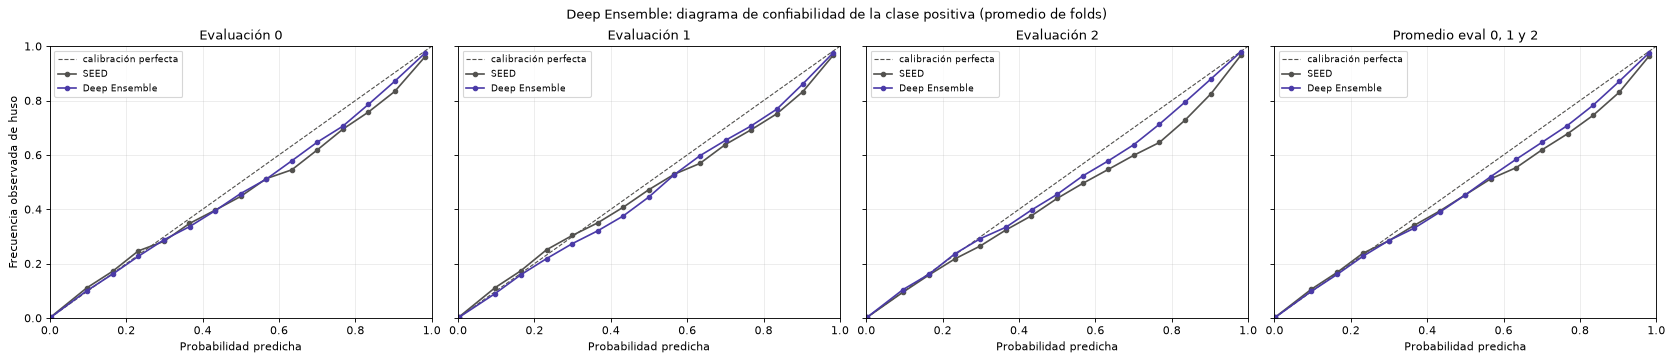

In [2]:
DETECTION = ['F1 evento (%)', 'precisión (%)', 'recall (%)', 'AUROC detección', 'AUPRC detección', 'NLL', 'Brier', 'ECE clase positiva']
display(report.by_evaluation(metrics, DETECTION))
display(metrics.set_index(['evaluación', 'fold'])[DETECTION].round(4))
show(report.plot_reliability(results, METHOD))

## 2. Curvas ROC

Curva promedio de los folds. *Detección*: huso vs fondo con la probabilidad. *Errores*: timesteps mal clasificados vs bien clasificados cerca de eventos, ordenados por cada medida de incertidumbre.

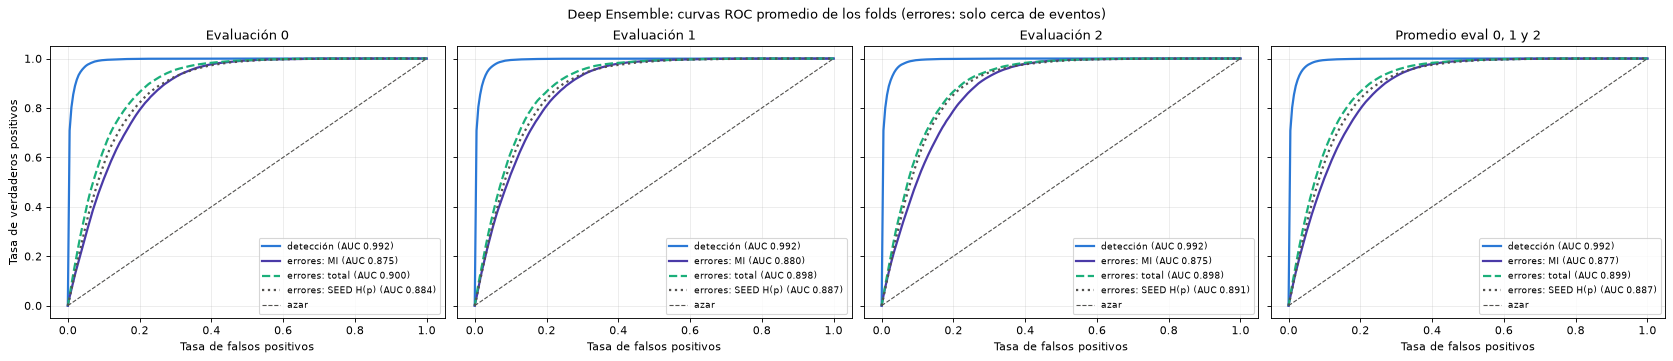

In [3]:
show(report.plot_roc(results, METHOD))

## 3. Descomposición de la incertidumbre

Entropía media en bits, en todo el registro y cerca de eventos, separada en aleatoria y epistémica (MI), con la incertidumbre de SEED como referencia.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
total (registro),0.06346 ± 0.0093,0.06498 ± 0.0055,0.06373 ± 0.0066,0.06406 ± 0.0068
aleatoria (registro),0.05936 ± 0.0088,0.06071 ± 0.0052,0.06027 ± 0.0063,0.06011 ± 0.0064
SEED H(p) (registro),0.06025 ± 0.0091,0.05881 ± 0.0089,0.06412 ± 0.006,0.06106 ± 0.0079
MI (registro),0.004106 ± 0.0009,0.004269 ± 0.00069,0.003459 ± 0.00047,0.003945 ± 0.00075
% epistémica (registro),6.477 ± 1.1,6.577 ± 0.98,5.436 ± 0.61,6.163 ± 1
total (cerca de eventos),0.2368 ± 0.015,0.2414 ± 0.013,0.2413 ± 0.0096,0.2398 ± 0.012
aleatoria (cerca de eventos),0.2221 ± 0.016,0.2269 ± 0.012,0.2292 ± 0.01,0.226 ± 0.012
SEED H(p) (cerca de eventos),0.2249 ± 0.0092,0.2264 ± 0.025,0.2328 ± 0.0087,0.228 ± 0.015
MI (cerca de eventos),0.01473 ± 0.0028,0.01446 ± 0.0022,0.01215 ± 0.0012,0.01378 ± 0.0024
% epistémica (cerca de eventos),6.241 ± 1.2,5.989 ± 0.85,5.048 ± 0.63,5.759 ± 1


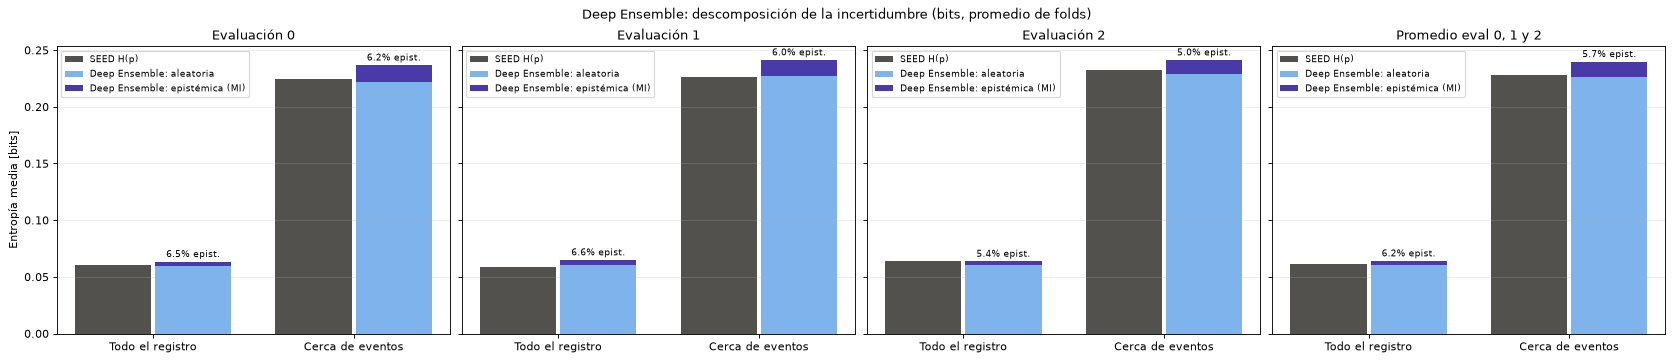

In [4]:
DECOMPOSITION = [c for c in metrics.columns if c.endswith('(registro)') or c.endswith('(cerca de eventos)')]
display(report.by_evaluation(metrics, DECOMPOSITION))
show(report.plot_decomposition(results, METHOD))

## 4. ¿La incertidumbre detecta los errores?

Errores por timestep cerca de eventos: AUROC y AUPRC de cada medida. El AUPRC se compara con la tasa de error (azar).

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
AUROC errores: total,0.9 ± 0.0054,0.8985 ± 0.0079,0.8983 ± 0.0038,0.8989 ± 0.0056
AUPRC errores: total,0.4144 ± 0.0089,0.4063 ± 0.0047,0.4098 ± 0.0042,0.4102 ± 0.0068
AUROC errores: aleatoria,0.8987 ± 0.0051,0.8962 ± 0.0081,0.8967 ± 0.0038,0.8972 ± 0.0056
AUPRC errores: aleatoria,0.4062 ± 0.0054,0.3954 ± 0.0074,0.4021 ± 0.0055,0.4012 ± 0.0073
AUROC errores: SEED H(p),0.8837 ± 0.0069,0.8868 ± 0.0072,0.8908 ± 0.0024,0.8871 ± 0.0063
AUPRC errores: SEED H(p),0.3703 ± 0.024,0.373 ± 0.017,0.3849 ± 0.017,0.3761 ± 0.019
AUROC errores: MI,0.8748 ± 0.0057,0.8803 ± 0.0097,0.8753 ± 0.0046,0.8768 ± 0.007
AUPRC errores: MI,0.3504 ± 0.011,0.3614 ± 0.012,0.3595 ± 0.013,0.3571 ± 0.012
azar errores,0.09916 ± 0.0043,0.09828 ± 0.0041,0.1001 ± 0.0046,0.0992 ± 0.0041


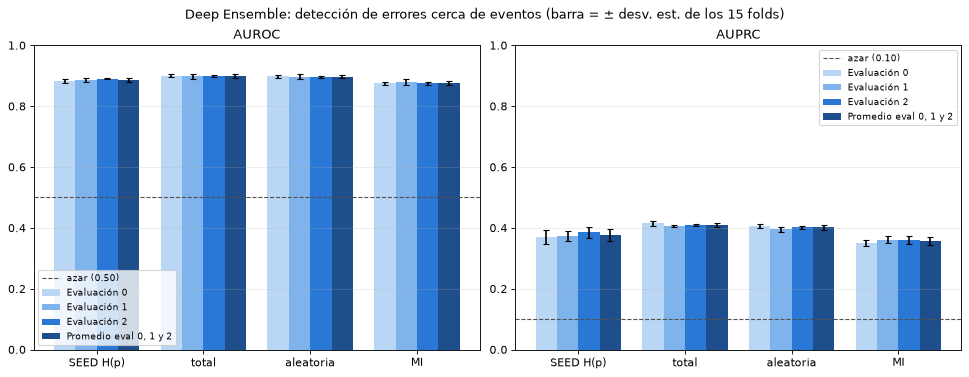

In [5]:
ERRORS = [c for c in metrics.columns if c.startswith('AUROC errores') or c.startswith('AUPRC errores')] + ['azar errores']
display(report.by_evaluation(metrics, ERRORS))
show(report.plot_error_detection(results, METHOD))

## 5. Dónde se concentra la incertidumbre

Entropía media por zona: bordes de los husos (±0.25 s del inicio o fin real), interior del huso y fondo.

Borde del huso
Interior del huso
Fondo


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,6.124 ± 0.34,6.124 ± 0.24,6.124 ± 0.36,6.124 ± 0.3
SEED H(p),0.4373 ± 0.015,0.4373 ± 0.033,0.4466 ± 0.014,0.4404 ± 0.021
aleatoria,0.4306 ± 0.017,0.4377 ± 0.014,0.4397 ± 0.013,0.436 ± 0.015
MI,0.02647 ± 0.0052,0.02532 ± 0.0045,0.02104 ± 0.0015,0.02428 ± 0.0045


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,2.055 ± 0.25,2.055 ± 0.19,2.055 ± 0.2,2.055 ± 0.2
SEED H(p),0.2824 ± 0.076,0.2848 ± 0.057,0.2954 ± 0.066,0.2876 ± 0.062
aleatoria,0.2767 ± 0.035,0.2799 ± 0.026,0.3036 ± 0.047,0.2868 ± 0.036
MI,0.02092 ± 0.0051,0.01983 ± 0.0042,0.01813 ± 0.0023,0.01963 ± 0.0039


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
% del registro,91.82 ± 0.53,91.82 ± 0.36,91.82 ± 0.55,91.82 ± 0.45
SEED H(p),0.03029 ± 0.011,0.02841 ± 0.0057,0.0336 ± 0.006,0.03076 ± 0.0077
aleatoria,0.02978 ± 0.0077,0.03064 ± 0.004,0.02964 ± 0.006,0.03002 ± 0.0057
MI,0.002229 ± 0.00061,0.002517 ± 0.00041,0.001959 ± 0.00035,0.002235 ± 0.00049


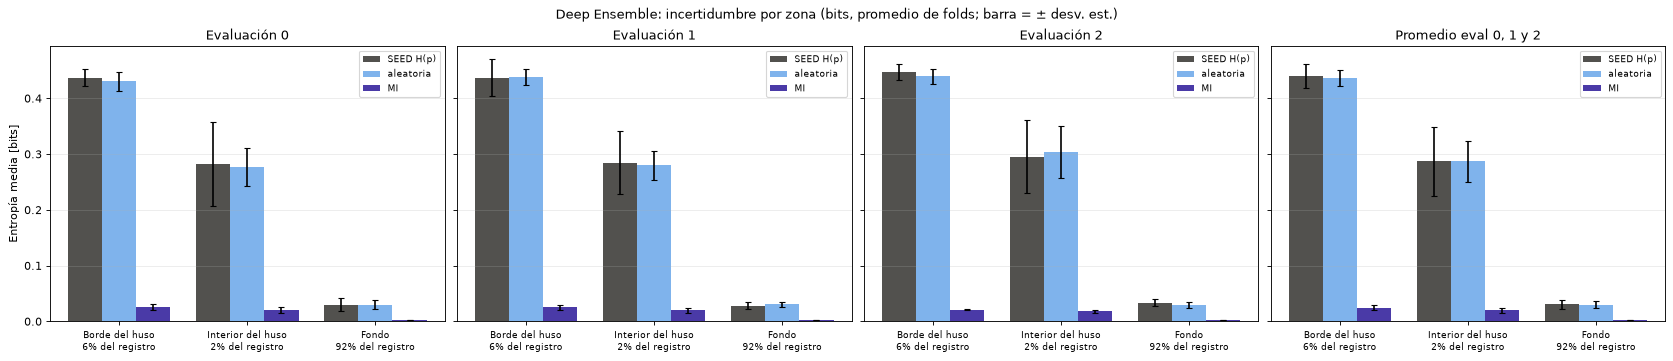

In [6]:
zones = results['zones']
for zone in ['Borde del huso', 'Interior del huso', 'Fondo']:
    print(zone)
    display(report.by_evaluation(zones[zones['zona'] == zone], [c for c in zones.columns if c not in ('evaluación', 'fold', 'zona')]))
show(report.plot_zones(results, METHOD))

## 6. Duración del evento vs incertidumbre

ρ es la correlación de Spearman entre la duración de cada evento predicho y su incertidumbre media (MI; para SEED, su entropía). ρ < 0: los eventos cortos son más inciertos.

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
ρ duración-incertidumbre,-0.471 ± 0.088,-0.4878 ± 0.088,-0.3725 ± 0.034,-0.4438 ± 0.087


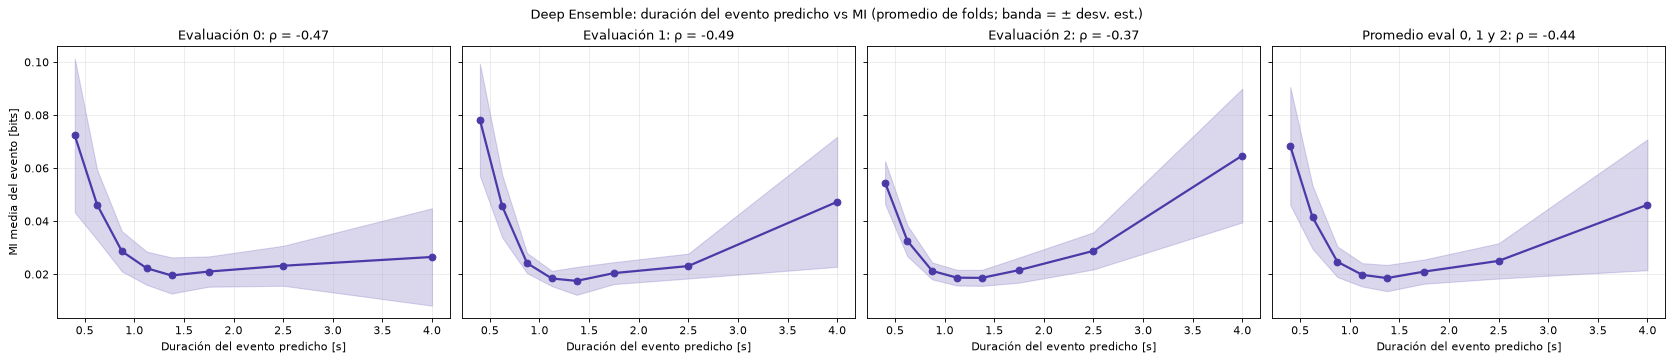

In [7]:
display(report.by_evaluation(metrics, ['ρ duración-incertidumbre']))
show(report.plot_duration(results, METHOD))

## 7. Aciertos, falsos positivos y falsos negativos

- **TP / FP (predicho)**: detecciones correctas y falsas, medidas en el tramo que el modelo predijo.
- **TP / FN (real)**: husos detectados y no detectados, medidos en el tramo real del huso (un FN no tiene tramo predicho). Los pares con IoU < 0.2 cuentan como FN, igual que en el F1.

Primero las medianas de cada medida, luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC con su azar), y al final los gráficos de cajón en percentil dentro del fold, con la línea de azar en 0.5. Comparar la *probabilidad media* entre FN y TP es casi circular (un FN es justamente un tramo con probabilidad baja).

Medianas por tipo de evento
FP vs TP (tramo predicho)
FN vs TP (tramo real)


eval 0                                                                                           eval 1                                                                                           eval 2                      \
              probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std) probabilidad media incertidumbre total   
grupo                                                                                                                                                                                                                                                    
TP (predicho)             0.8743              0.4268    0.4008          0.0198                          0.0484             0.8719              0.4336    0.4141          0.0165                          0.0438             0.8718              0.4389   
FP (predicho)             0.6173              0.9412    0.8392          0.0550                          0.1246             0.6188              0.9422    0.8314          0.0545                          0.1243             0.6278              0.9341   
TP (real)                 0.8622              0.3985    0.3756          0.0180                          0.0437             0.8654              0.3982    0.3818          0.0146                          0.0389             0.8602              0.4073   
FN (real)                 0.1962              0.6652    0.6235          0.0316                          0.0756             0.2022              0.6693    0.6180          0.0360                          0.0814             0.1936              0.6488   

                                                                        promedio eval 0, 1 y 2                                                                                
              aleatoria epistémica (MI) dispersión entre muestras (std)     probabilidad media incertidumbre total aleatoria epistémica (MI) dispersión entre muestras (std)  
grupo                                                                                                                                                                         
TP (predicho)    0.4215          0.0152                          0.0423                 0.8727              0.4331    0.4116          0.0171                          0.0448  
FP (predicho)    0.8633          0.0431                          0.1098                 0.6209              0.9387    0.8468          0.0501                          0.1191  
TP (real)        0.3915          0.0135                          0.0385                 0.8628              0.4014    0.3822          0.0153                          0.0404  
FN (real)        0.6043          0.0256                          0.0671                 0.1969              0.6619    0.6155          0.0308                          0.0738

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1578 ± 0.043,0.1558 ± 0.022,0.155 ± 0.037,0.1562 ± 0.033
AUROC probabilidad media,0.8584 ± 0.016,0.8554 ± 0.0096,0.8566 ± 0.018,0.8568 ± 0.014
AUPRC probabilidad media,0.4704 ± 0.091,0.4788 ± 0.034,0.4633 ± 0.1,0.4708 ± 0.075
AUROC incertidumbre total,0.862 ± 0.016,0.8599 ± 0.0081,0.8614 ± 0.017,0.8611 ± 0.013
AUPRC incertidumbre total,0.4829 ± 0.096,0.479 ± 0.027,0.4666 ± 0.097,0.4762 ± 0.075
AUROC aleatoria,0.856 ± 0.016,0.8521 ± 0.0029,0.8566 ± 0.02,0.8549 ± 0.014
AUPRC aleatoria,0.4593 ± 0.11,0.4543 ± 0.034,0.4446 ± 0.094,0.4527 ± 0.079
AUROC epistémica (MI),0.7773 ± 0.014,0.7876 ± 0.0066,0.7831 ± 0.016,0.7826 ± 0.013
AUPRC epistémica (MI),0.366 ± 0.074,0.3689 ± 0.038,0.3604 ± 0.083,0.3651 ± 0.063
AUROC dispersión entre muestras (std),0.824 ± 0.011,0.8228 ± 0.0067,0.8289 ± 0.014,0.8252 ± 0.01


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1676 ± 0.045,0.1675 ± 0.021,0.1756 ± 0.032,0.1702 ± 0.032
AUROC probabilidad media,0.9629 ± 0.015,0.9622 ± 0.0092,0.9665 ± 0.026,0.9638 ± 0.017
AUPRC probabilidad media,0.9404 ± 0.024,0.9415 ± 0.014,0.9452 ± 0.041,0.9424 ± 0.026
AUROC incertidumbre total,0.6461 ± 0.056,0.6528 ± 0.047,0.6331 ± 0.042,0.644 ± 0.046
AUPRC incertidumbre total,0.2352 ± 0.041,0.2341 ± 0.011,0.2383 ± 0.014,0.2359 ± 0.024
AUROC aleatoria,0.6466 ± 0.053,0.6456 ± 0.053,0.6279 ± 0.042,0.6401 ± 0.047
AUPRC aleatoria,0.2456 ± 0.044,0.239 ± 0.017,0.2381 ± 0.011,0.2409 ± 0.026
AUROC epistémica (MI),0.6296 ± 0.077,0.6874 ± 0.017,0.6609 ± 0.058,0.6593 ± 0.058
AUPRC epistémica (MI),0.2403 ± 0.047,0.2785 ± 0.033,0.2804 ± 0.054,0.2664 ± 0.046
AUROC dispersión entre muestras (std),0.6387 ± 0.068,0.6781 ± 0.027,0.6543 ± 0.051,0.6571 ± 0.05


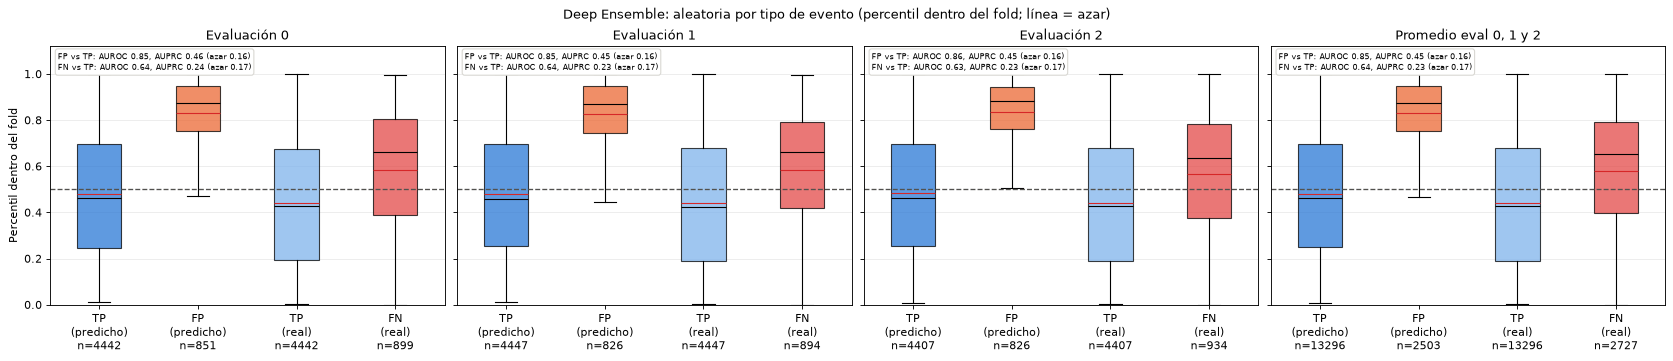

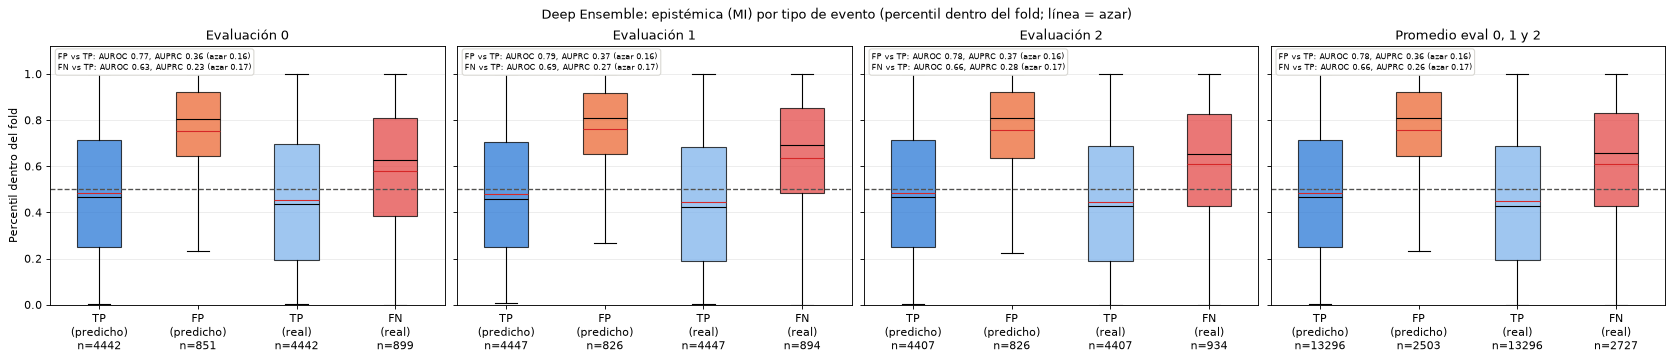

In [8]:
events = results['events']
print('Medianas por tipo de evento')
display(report.event_medians(events))
print('FP vs TP (tramo predicho)')
display(report.event_separation(events, 'TP (predicho)', 'FP (predicho)'))
print('FN vs TP (tramo real)')
display(report.event_separation(events, 'TP (real)', 'FN (real)'))
for figure in report.plot_event_boxes(results, METHOD):
    show(figure)

## 8. Derivar a revisión las detecciones más inciertas

Si se manda a revisión el x% de detecciones con más incertidumbre, ¿qué precisión tiene lo que se acepta automáticamente y qué parte de los falsos positivos se captura?

eval 0
eval 1
eval 2
promedio eval 0, 1 y 2


precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.2            84.2                84.2                0.0             0.0                 0.0
5.0                          85.8            85.6                86.2               14.2            13.2                17.2
10.0                         87.6            87.1                88.4               29.5            26.8                34.1
20.0                         90.9            89.4                91.9               53.3            46.3                59.8
30.0                         93.5            91.5                94.9               71.3            62.3                78.2

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.4            84.4                84.4                0.0             0.0                 0.0
5.0                          86.2            85.9                86.6               15.8            13.8                18.6
10.0                         87.7            87.2                88.6               29.3            26.2                34.5
20.0                         91.2            89.9                92.0               54.7            48.2                59.0
30.0                         94.0            92.1                94.9               73.2            64.6                77.5

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.5            84.5                84.5                0.0             0.0                 0.0
5.0                          86.2            86.0                86.3               15.4            14.1                16.1
10.0                         87.7            87.5                88.6               28.8            27.3                34.2
20.0                         90.9            89.7                92.3               53.0            46.9                60.2
30.0                         94.1            91.7                95.1               73.3            62.4                78.0

precisión aceptado (%)                                     % de FP capturados                                    
medida                  SEED H(p) epistémica (MI) incertidumbre total          SEED H(p) epistémica (MI) incertidumbre total
% derivado                                                                                                                  
0.0                          84.4            84.4                84.4                0.0             0.0                 0.0
5.0                          86.0            85.8                86.4               15.1            13.7                17.3
10.0                         87.7            87.3                88.5               29.2            26.8                34.2
20.0                         91.0            89.7                92.0               53.7            47.1                59.7
30.0                         93.9            91.8                95.0               72.6            63.1                77.9

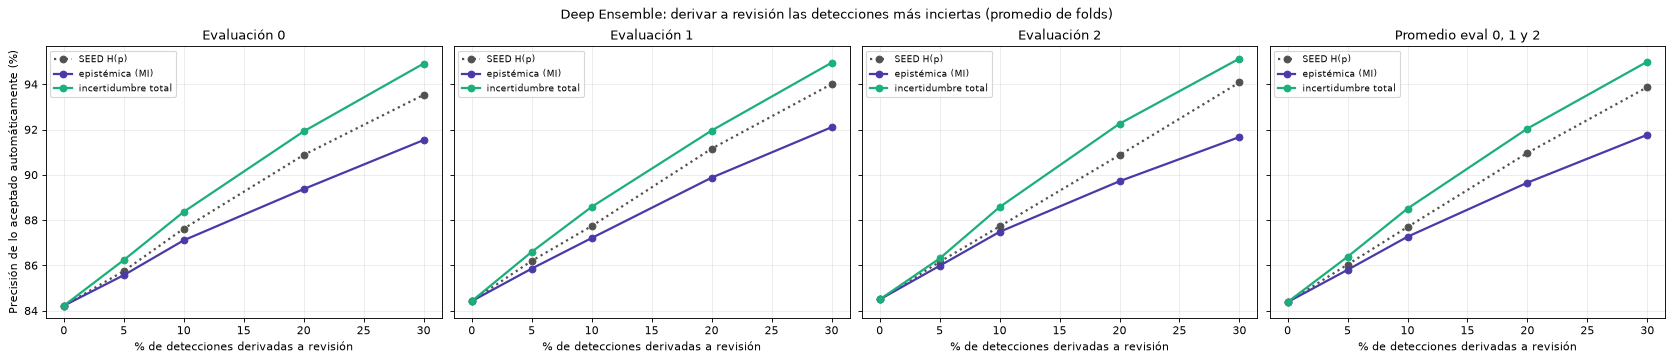

In [9]:
deferral = results['deferral'].dropna(subset=['% derivado'])
for label, part in [(f'eval {e}', deferral[deferral['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), deferral)]:
    print(label)
    display(part.groupby(['medida', '% derivado'])[['precisión aceptado (%)', '% de FP capturados']].mean().round(1).unstack('medida'))
show(report.plot_deferral(results, METHOD))

## 9. Descartar automáticamente las detecciones más inciertas

Sin revisión humana: se eliminan las detecciones con mayor incertidumbre (MI; para SEED, entropía). Los aciertos eliminados pasan a ser falsos negativos. Para que el F1 suba, más de ~58% de lo descartado debe ser FP (con F1 ≈ 83%, el equilibrio es 1 − F1/2).

FP descartados  TP descartados  % FP en lo descartado  cambio F1 (puntos)
medida              % descartado                                                                           
SEED H(p)           0.5                     2.93            2.33                  55.33               -0.01
                    1.0                     5.53            5.00                  51.54               -0.06
                    2.0                    10.67           10.40                  49.99               -0.16
                    5.0                    25.13           27.60                  47.03               -0.55
                    10.0                   48.53           56.87                  45.40               -1.30
                    20.0                   89.87          120.73                  41.97               -3.50
epistémica (MI)     0.5                     2.73            2.53                  51.67               -0.03
                    1.0                     4.87            5.67                  45.80               -0.12
                    2.0                    10.33           10.73                  48.69               -0.19
                    5.0                    22.87           29.87                  42.63               -0.78
                    10.0                   44.47           60.93                  41.57               -1.71
                    20.0                   78.40          132.20                  36.72               -4.68
incertidumbre total 0.5                     3.27            2.00                  61.33                0.02
                    1.0                     6.33            4.20                  59.77                0.02
                    2.0                    12.00            9.07                  56.38               -0.03
                    5.0                    28.60           24.13                  53.59               -0.22
                    10.0                   56.27           49.13                  52.74               -0.54
                    20.0                   98.80          111.80                  46.27               -2.56

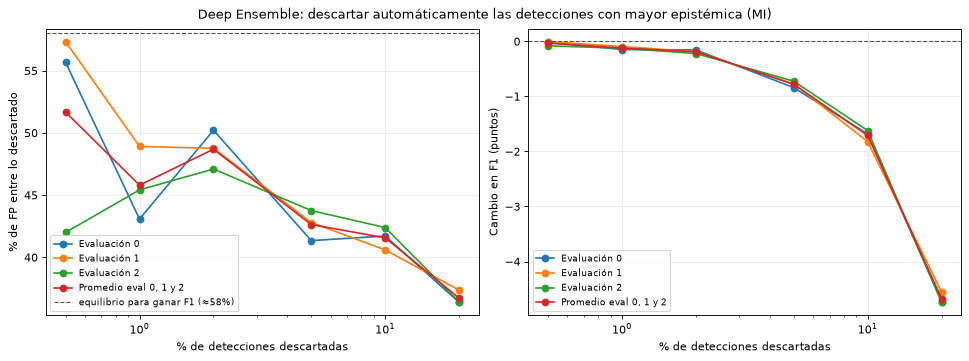

In [10]:
rejection = results['deferral'].dropna(subset=['% descartado'])
display(rejection.groupby(['medida', '% descartado'])[['FP descartados', 'TP descartados', '% FP en lo descartado', 'cambio F1 (puntos)']].mean().round(2))
show(report.plot_rejection(results, METHOD))

## 10. Información del método

F1 por evento de cada miembro del ensamble, por fold.

In [11]:
info = results['info']
display(info.set_index(['evaluación', 'fold']).round(3))
display(report.by_evaluation(info))

F1 miembro seed 42  F1 miembro seed 1  F1 miembro seed 2  F1 miembro seed 3  F1 miembro seed 4
evaluación fold                                                                                                
0          0                 82.321             81.843             82.881             83.531             82.995
           1                 81.702             80.855             80.841             81.262             81.212
           2                 83.053             83.643             83.029             83.794             84.185
           3                 83.084             83.051             83.403             83.705             83.923
           4                 81.734             84.529             85.352             84.365             82.278
1          0                 83.141             82.368             82.762             82.221             82.429
           1                 83.657             83.472             83.557             84.049             84.344
           2                 81.720             82.359             83.291             83.403             83.333
           3                 82.332             82.275             82.609             81.901             82.476
           4                 83.775             82.236             82.871             82.178             83.111
2          0                 82.400             82.543             82.095             80.429             81.273
           1                 81.966             82.455             82.856             83.495             82.558
           2                 82.330             82.163             82.108             81.485             82.533
           3                 83.455             83.341             82.762             82.986             83.256
           4                 84.011             85.125             85.192             85.081             83.990

,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
F1 miembro seed 42,82.38 ± 0.68,82.93 ± 0.88,82.83 ± 0.86,82.71 ± 0.79
F1 miembro seed 1,82.78 ± 1.5,82.54 ± 0.52,83.13 ± 1.2,82.82 ± 1.1
F1 miembro seed 2,83.1 ± 1.6,83.02 ± 0.39,83 ± 1.3,83.04 ± 1.1
F1 miembro seed 3,83.33 ± 1.2,82.75 ± 0.93,82.7 ± 1.8,82.93 ± 1.3
F1 miembro seed 4,82.92 ± 1.2,83.14 ± 0.78,82.72 ± 1,82.93 ± 0.96


## Ejemplo temporal

Mismo segmento que el ejemplo de Laplace de la presentación: evaluación 0, fold 1, registro 261, 20 s desde el segundo 60. Paneles: señal EEG con los husos del experto sombreados, etiqueta real, predicción de SEED, predicción de Deep Ensemble y su MI en bits.

In [12]:
import os

import h5py
import numpy as np

from eeg_uq.method_summary import load_fold

DATA_ROOT = Path(os.environ.get('EEG_DATA_ROOT', Path.home() / 'Downloads' / 'data' / 'data'))
SR = 200
EXAMPLE_EVALUATION, EXAMPLE_FOLD, EXAMPLE_SAMPLE, EXAMPLE_START_S = 0, 0, 261, 60
GREEN, BLUE = '#2ca25f', '#2a78d6'

seed_fold = load_fold(report.method_path('SEED', EXAMPLE_EVALUATION, EXAMPLE_FOLD), 'seed')
method_fold = load_fold(report.method_path(METHOD, EXAMPLE_EVALUATION, EXAMPLE_FOLD), 'sampling')
row = int(np.flatnonzero(method_fold['sample_id'] == EXAMPLE_SAMPLE)[0])
seed_row = int(np.flatnonzero(seed_fold['sample_id'] == EXAMPLE_SAMPLE)[0])
window = slice(EXAMPLE_START_S * SR, (EXAMPLE_START_S + 20) * SR)
with h5py.File(DATA_ROOT / 'moda_moda.h5', 'r') as source:
    signal = np.asarray(source['signals'][EXAMPLE_SAMPLE], dtype=float)[window]
labels = method_fold['y_true'][row][window]
times = np.arange(len(labels)) / SR
mi = method_fold['mi'][row][window]
print(f'MI en el segmento: máximo {mi.max():.4f} bits, media {mi.mean():.4f} bits')

panels = [('SEED\ny_predict', seed_fold['processed_pred'][seed_row][window], 'binario'),
          ('Deep Ens.\ny_predict', method_fold['processed_pred'][row][window], 'binario'),
          ('Deep Ens.\nMI (bits)', mi, 'curva')]
fig, axes = plt.subplots(2 + len(panels), 1, figsize=(14, 8.7), sharex=True,
                         gridspec_kw={'height_ratios': [2.6, 0.9, 0.9, 0.9, 0.9]}, constrained_layout=True)
fig.suptitle(f'{METHOD}: detección e incertidumbre — fold {EXAMPLE_FOLD + 1}, registro {EXAMPLE_SAMPLE}, segmento de 20 s')
axes[0].plot(times, signal, color='#263238', lw=0.6)
axes[0].set_ylabel('EEG (µV)')
axes[1].step(times, labels, where='post', color='black', lw=1.2)
axes[1].set(ylabel='y_true', ylim=(-0.1, 1.1))
for ax, (label, values, kind) in zip(axes[2:], panels):
    if kind == 'binario':
        ax.step(times, values, where='post', color=BLUE, lw=1.3)
        ax.set_yticks([0, 1], ['Fondo', 'Evento'])
        ax.set_ylim(-0.1, 1.1)
    else:
        ax.plot(times, values, color='#d81b60', lw=1.2)
    ax.set_ylabel(label)
edges = np.diff(np.r_[0, labels, 0])
for ax in axes:
    for begin, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
        ax.axvspan(times[begin], times[min(stop, len(times) - 1)], color=GREEN, alpha=0.15, lw=0)
    ax.grid(alpha=0.25)
axes[-1].set(xlabel='Tiempo dentro del segmento (s)', xlim=(0, 20))
show(fig)

Salida oculta en el repositorio: muestra señal EEG cruda de los datos privados (MODA).
Ejecuta la celda localmente con los datos para verla.


## Ejemplos temporales por tipo de evento

Segmentos de 20 s centrados en un evento del método (evaluación 0, fold 1), uno por tipo:

- **TP**: el método detectó un huso real.
- **FP**: el método detectó un huso que el experto no marcó.
- **FN**: el experto marcó un huso que el método no detectó.

Para cada tipo se muestran dos casos: uno con **MI alta** (percentil 90 de su tipo) y otro con **MI baja** (percentil 10). Las líneas naranjas punteadas marcan el evento del ejemplo; el verde, los husos del experto. Todos los paneles de MI usan la misma escala para poder compararlos. Solo se consideran eventos de al menos 0,5 s.

In [13]:
PREFIX = 'Deep Ens.'
EXAMPLE_PERCENTILES = (('MI alta', 0.9), ('MI baja', 0.1))
ORANGE = '#eb6834'
row_of = {int(s): r for r, s in enumerate(method_fold['sample_id'])}
seed_row_of = {int(s): r for r, s in enumerate(seed_fold['sample_id'])}
length = method_fold['y_true'].shape[1]

# MI media de cada evento del método: TP y FP en el tramo predicho, FN en el tramo real.
records = []
for sample, status, p0, p1, t0, t1 in zip(method_fold['event_sample_id'], method_fold['event_status'],
                                          method_fold['event_pred_start'], method_fold['event_pred_end'],
                                          method_fold['event_true_start'], method_fold['event_true_end']):
    if status in ('TP', 'FP'):
        start, end = int(p0), int(p1)
    elif status == 'FN':
        start, end = int(t0), int(t1)
    else:
        continue
    if end - start < SR // 2:
        continue
    row = row_of[int(sample)]
    records.append({'tipo': str(status), 'registro': int(sample), 'inicio': start, 'fin': end,
                    'MI media': float(method_fold['mi'][row, start:end].mean())})
fold_events = pd.DataFrame(records)

examples = []
for kind in ('TP', 'FP', 'FN'):
    group = fold_events[fold_events['tipo'] == kind].sort_values('MI media').reset_index(drop=True)
    for label, quantile in EXAMPLE_PERCENTILES:
        pick = group.iloc[int(round(quantile * (len(group) - 1)))]
        center = (pick['inicio'] + pick['fin']) // 2
        begin = int(np.clip(center - 10 * SR, 0, length - 20 * SR))
        examples.append((kind, label, pick, slice(begin, begin + 20 * SR)))
display(pd.DataFrame([{'tipo': k, 'caso': l, 'registro': p['registro'], 'MI media (bits)': round(p['MI media'], 4),
                       'duración (s)': (p['fin'] - p['inicio']) / SR} for k, l, p, _ in examples]))

mi_max = max(method_fold['mi'][row_of[int(p['registro'])]][w].max() for _, _, p, w in examples) * 1.1
with h5py.File(DATA_ROOT / 'moda_moda.h5', 'r') as source:
    for kind, label, pick, window in examples:
        sample = int(pick['registro'])
        row, seed_row = row_of[sample], seed_row_of[sample]
        signal = np.asarray(source['signals'][sample], dtype=float)[window]
        labels = method_fold['y_true'][row][window]
        times = np.arange(len(labels)) / SR
        focus = ((pick['inicio'] - window.start) / SR, (pick['fin'] - window.start) / SR)
        rows = [('SEED\ny_predict', seed_fold['processed_pred'][seed_row][window]),
                (PREFIX + '\ny_predict', method_fold['processed_pred'][row][window])]
        fig, axes = plt.subplots(5, 1, figsize=(14, 8.2), sharex=True,
                                 gridspec_kw={'height_ratios': [2.4, 0.8, 0.8, 0.8, 1.0]}, constrained_layout=True)
        fig.suptitle(f'{METHOD} · {kind} con {label} (MI media del evento {pick["MI media"]:.3f} bits) — registro {sample}, '
                     f'{window.start / SR:.0f}–{window.stop / SR:.0f} s')
        axes[0].plot(times, signal, color='#263238', lw=0.6)
        axes[0].set_ylabel('EEG (µV)')
        axes[1].step(times, labels, where='post', color='black', lw=1.2)
        axes[1].set(ylabel='y_true', ylim=(-0.1, 1.1))
        for ax, (name, values) in zip(axes[2:4], rows):
            ax.step(times, values, where='post', color=BLUE, lw=1.3)
            ax.set_yticks([0, 1], ['Fondo', 'Evento'])
            ax.set(ylabel=name, ylim=(-0.1, 1.1))
        axes[4].plot(times, method_fold['mi'][row][window], color='#d81b60', lw=1.2)
        axes[4].set(ylabel=PREFIX + '\nMI (bits)', ylim=(0, mi_max))
        edges = np.diff(np.r_[0, labels, 0])
        for ax in axes:
            for begin, stop in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)):
                ax.axvspan(times[begin], times[min(stop, len(times) - 1)], color=GREEN, alpha=0.15, lw=0)
            for edge in focus:
                ax.axvline(edge, color=ORANGE, ls='--', lw=1.6)
            ax.grid(alpha=0.25)
        axes[-1].set(xlabel='Tiempo dentro del segmento (s)', xlim=(0, 20))
        show(fig)

Salida oculta en el repositorio: muestra señal EEG cruda de los datos privados (MODA).
Ejecuta la celda localmente con los datos para verla.


## Hallazgos

Cifras como eval 0 / eval 1 / eval 2 / promedio de las tres (15 folds de test); un solo número es el promedio.

1. **El mejor F1 de todos los métodos:** 83.6% / 83.8% / 83.4% / 83.6% (SEED 82.7%). Supera al promedio de sus propios miembros (~82.9%) en los 15 folds, y a SEED en 14 de 15.
2. **La mejor calibración:** ECE 0.004 / 0.003 / 0.004 / 0.004 (SEED 0.006) y NLL 0.047 (SEED 0.051).
3. **La mejor incertidumbre total para detectar errores:** AUROC 0.900 / 0.899 / 0.898 / 0.899 y AUPRC 0.41, por encima de SEED (0.894).
4. **Parte epistémica de 5.8%**, concentrada en los bordes de los husos. Su MI detecta errores con AUROC 0.877 y AUPRC 0.36 (azar 0.10).
5. **Falsos positivos:** la incertidumbre total los separa con AUROC 0.86 (la mejor), y la MI con 0.78. **Falsos negativos:** la MI llega a AUROC 0.66 y AUPRC 0.27 (azar 0.17); su MI en los husos perdidos es el doble que en los aciertos. Con Neural Process, es el único que detecta parte de los errores silenciosos.
6. **Uso práctico:** derivar a revisión el 20% más incierto captura el 60% de los FP y sube la precisión de lo aceptado de 84.4% a 92.0%. Descartar por MI no mejora el F1.

**Conclusión.** El método más completo: mejora a la vez la detección, la calibración y la capacidad de señalar errores. El costo es entrenar cinco SEED por fold.